# 03 · Modelling and hyperparameter tuning
**Machine Learning and Data Analytics, Coursework 1 · Student ID: 18503**

Four tasks, all trained on the **training blocks only** (the test blocks are used once, in notebook 04):

| Task | Type | Target | Main metric |
|---|---|---|---|
| A | Binary classification | `any_fishing` | PR-AUC (average precision), plus ROC-AUC |
| B | Regression (rows with fishing) | `log_fishing_hours` | RMSE on the log scale |
| C | 16-class classification | `geartype` | Macro-F1 |
| D | Clustering (unsupervised) | fishing grounds | Silhouette |

Model comparison uses **GroupKFold cross-validation by geographic block**, so scores reflect performance on unseen places. Hyperparameters are tuned with randomised search on a subsample of the training rows to keep the run time reasonable; the winner is then refitted on all training rows.

Set `CW_FAST=1` in the environment for a quick smoke test (smaller samples, fewer search iterations).

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import features as F
from src import plotstyle as P
P.apply()

DATA = ROOT / "data" / "processed" / "fishing_sample.parquet"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
SEED = F.SEED
FAST = os.environ.get("CW_FAST") == "1"   # quick smoke test; leave unset for real results

In [2]:
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_validate
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import joblib

df = F.prepare(F.load_sample(DATA))
train_idx, _ = F.geo_split(df)                       # test rows are deliberately not kept here
train = df.iloc[train_idx].reset_index(drop=True)
print(f"Training rows: {len(train):,} in {train['block'].nunique()} blocks | FAST mode: {FAST}")

N_TUNE = 15000 if FAST else 60000
N_ITER = 2 if FAST else 10
N_FOLDS = 3
tune = train.sample(min(N_TUNE, len(train)), random_state=SEED).reset_index(drop=True)
RESULTS = {}

def make_pipe(model, with_activity=False, with_vessel=True, scale=True):
    fs = F.feature_sets(with_activity, with_vessel)
    pipe = Pipeline([("prep", F.make_preprocessor(fs["num"], fs["cat"], scale=scale)), ("model", model)])
    return pipe, fs["num"] + fs["cat"]

def cv_table(models, data, target, scoring, with_activity=False, with_vessel=True):
    cv = GroupKFold(n_splits=N_FOLDS)
    rows = {}
    for name, model in models.items():
        pipe, cols = make_pipe(model, with_activity, with_vessel)
        t0 = time.time()
        r = cross_validate(pipe, data[cols], data[target], groups=data["block"], cv=cv, scoring=scoring, n_jobs=1)
        rows[name] = {f"{k[5:]}": r[k].mean() for k in r if k.startswith("test_")}
        rows[name].update({f"{k[5:]}_sd": r[k].std() for k in r if k.startswith("test_")})
        rows[name]["fit_s"] = round(time.time() - t0, 1)
    return pd.DataFrame(rows).T

def tune_model(model, params, data, cols, target, scoring, with_activity=False):
    pipe, cols = make_pipe(model, with_activity)
    s = RandomizedSearchCV(pipe, params, n_iter=N_ITER, scoring=scoring, cv=GroupKFold(n_splits=N_FOLDS),
                           random_state=SEED, n_jobs=1, refit=True)
    s.fit(data[cols], data[target], groups=data["block"])
    return s

Training rows: 237,895 in 376 blocks | FAST mode: False


## Task A · Will any fishing occur? (binary classification)
About two thirds of rows have no fishing, so accuracy would be misleading. We report PR-AUC (average precision) and ROC-AUC, plus F1 and balanced accuracy at the default threshold. `Dummy` always predicts the class prior and sets the floor.

### A1. Baseline comparison (feature set A, block-grouped CV)

In [3]:
scoreA = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "bal_acc": "balanced_accuracy"}
modelsA = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=60 if FAST else 100, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "Hist gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
}
cvA = cv_table(modelsA, tune, "any_fishing", scoreA)
RESULTS["A_baseline_cv"] = cvA.round(4).to_dict("index")
cvA[["roc_auc", "roc_auc_sd", "pr_auc", "pr_auc_sd", "f1", "bal_acc", "fit_s"]].round(3)

,roc_auc,roc_auc_sd,pr_auc,pr_auc_sd,f1,bal_acc,fit_s
Dummy (prior),0.500,0.000,0.308,0.027,0.000,0.500,0.9
Logistic regression,0.705,0.026,0.470,0.046,0.540,0.654,1.2
Random forest,0.722,0.015,0.506,0.037,0.319,0.576,4.5
Hist gradient boosting,0.725,0.016,0.517,0.042,0.348,0.587,4.3


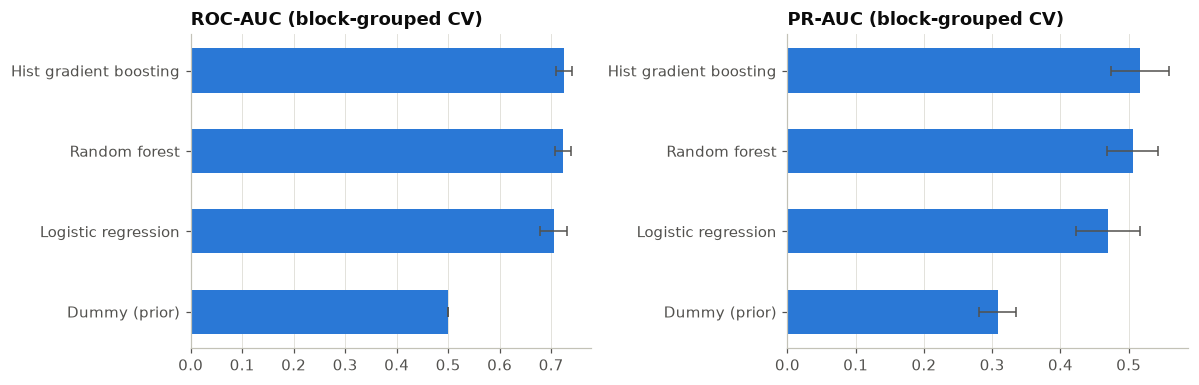

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, (m, t) in zip(ax, [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC")]):
    d = cvA[m].sort_values()
    a.barh(d.index, d.values, xerr=cvA.loc[d.index, m + "_sd"], color=P.BLUE, height=0.55,
           error_kw=dict(ecolor=P.MUTED, capsize=3, lw=1))
    a.set_title(f"{t} (block-grouped CV)"); a.grid(axis="y", visible=False)
fig.tight_layout(); P.save(fig, FIG / "13_taskA_baselines.png")

### A2. Hyperparameter tuning (random search, scoring = PR-AUC)

In [5]:
hgb_params = {"model__learning_rate": loguniform(0.03, 0.3), "model__max_leaf_nodes": randint(15, 80),
              "model__min_samples_leaf": randint(20, 200), "model__l2_regularization": loguniform(1e-3, 10),
              "model__max_iter": randint(100, 400)}
rf_params = {"model__n_estimators": randint(60, 200) if FAST else randint(100, 250), "model__max_depth": randint(6, 20),
             "model__min_samples_leaf": randint(5, 40), "model__max_features": ["sqrt", 0.5]}

searchA = {
    "Hist gradient boosting": tune_model(HistGradientBoostingClassifier(random_state=SEED), hgb_params, tune, None, "any_fishing", "average_precision"),
    "Random forest": tune_model(RandomForestClassifier(n_jobs=-1, random_state=SEED), rf_params, tune, None, "any_fishing", "average_precision"),
}
tunedA = pd.DataFrame({k: {"cv_pr_auc_before": cvA.loc[k, "pr_auc"], "cv_pr_auc_tuned": v.best_score_} for k, v in searchA.items()}).T.round(4)
for k, v in searchA.items():
    print(k, "->", {p.replace("model__", ""): (round(x, 4) if isinstance(x, float) else x) for p, x in v.best_params_.items()})
RESULTS["A_tuned"] = {k: {"cv_pr_auc": float(v.best_score_), "params": {p: (float(x) if isinstance(x, (int, float, np.floating, np.integer)) else x) for p, x in v.best_params_.items()}} for k, v in searchA.items()}
tunedA

Hist gradient boosting -> {'l2_regularization': np.float64(0.0042), 'learning_rate': np.float64(0.043), 'max_iter': 187, 'max_leaf_nodes': 38, 'min_samples_leaf': 150}
Random forest -> {'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 33, 'n_estimators': 114}


,cv_pr_auc_before,cv_pr_auc_tuned
Hist gradient boosting,0.5168,0.5175
Random forest,0.5056,0.5187


### A3. Does total activity (`hours`, `mmsi_present`) help? (feature set A vs B)
`hours` contains the fishing time, so set B is an easier problem: it shows how much information is carried by activity itself, not what is deployable.

In [6]:
bestA_name = max(searchA, key=lambda k: searchA[k].best_score_)
bestA_params = searchA[bestA_name].best_params_
print("Best model for Task A:", bestA_name)

def with_params(est, params):
    e = clone(est); e.set_params(**{k.replace("model__", ""): v for k, v in params.items()}); return e

base_estA = searchA[bestA_name].best_estimator_.named_steps["model"]
abl = {}
for label, act in [("Set A (location, season, gear, flag, vessel)", False), ("Set B (A + hours, mmsi_present)", True)]:
    abl[label] = cv_table({bestA_name: clone(base_estA)}, tune, "any_fishing", scoreA, with_activity=act).iloc[0]
ablA = pd.DataFrame(abl).T[["roc_auc", "pr_auc", "f1", "bal_acc"]].round(3)
RESULTS["A_activity_ablation"] = ablA.to_dict("index")
ablA

Best model for Task A: Random forest


,roc_auc,pr_auc,f1,bal_acc
"Set A (location, season, gear, flag, vessel)",0.729,0.519,0.293,0.57
"Set B (A + hours, mmsi_present)",0.899,0.799,0.737,0.81


In [7]:
# Final Task A models: refit on ALL training rows
final_A = {}
for label, act in [("A", False), ("B", True)]:
    pipe, cols = make_pipe(clone(base_estA), with_activity=act)
    pipe.fit(train[cols], train["any_fishing"])
    final_A[label] = (pipe, cols)
    joblib.dump({"pipeline": pipe, "columns": cols}, MODELS / f"occurrence_{label}.joblib", compress=3)
    print(f"occurrence_{label}.joblib  {(MODELS / f'occurrence_{label}.joblib').stat().st_size/1e6:.1f} MB")

occurrence_A.joblib  6.0 MB
occurrence_B.joblib  6.2 MB


## Task B · How much fishing, where it occurs? (regression)
Trained only on rows with fishing (`fishing_hours > 0`), target `log1p(fishing_hours)`. RMSE and MAE are on the log scale; R² is the share of variance explained. The two-part model combines A and B: expected effort = P(fishing) × predicted hours.

In [8]:
pos = train[train["any_fishing"] == 1].reset_index(drop=True)
tune_pos = pos.sample(min(N_TUNE, len(pos)), random_state=SEED).reset_index(drop=True)
print(f"Rows with fishing in training blocks: {len(pos):,}; tuning subsample: {len(tune_pos):,}")

scoreB = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
modelsB = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Ridge regression": Ridge(alpha=1.0),
    "Random forest": RandomForestRegressor(n_estimators=60 if FAST else 100, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "Hist gradient boosting": HistGradientBoostingRegressor(random_state=SEED),
}
cvB = cv_table(modelsB, tune_pos, "log_fishing_hours", scoreB)
for m in ["rmse", "mae"]:
    cvB[m] = -cvB[m]
RESULTS["B_baseline_cv"] = cvB.round(4).to_dict("index")
cvB[["rmse", "mae", "r2", "fit_s"]].round(3)

Rows with fishing in training blocks: 73,445; tuning subsample: 60,000


,rmse,mae,r2,fit_s
Dummy (mean),1.362,1.113,-0.035,0.7
Ridge regression,1.277,1.035,0.087,0.8
Random forest,1.268,1.014,0.099,8.9
Hist gradient boosting,1.246,1.004,0.130,3.0


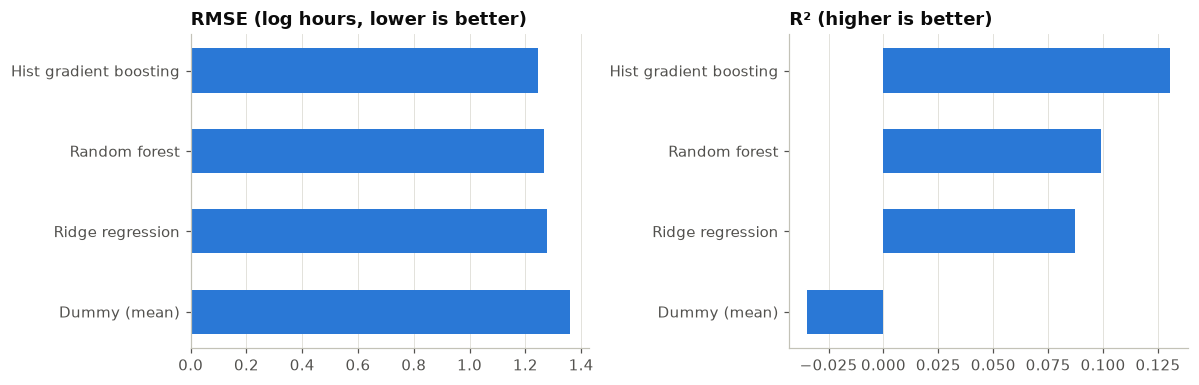

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, (m, t) in zip(ax, [("rmse", "RMSE (log hours, lower is better)"), ("r2", "R² (higher is better)")]):
    d = cvB[m].sort_values(ascending=(m == "r2"))
    a.barh(d.index, d.values, color=P.BLUE, height=0.55); a.set_title(t); a.grid(axis="y", visible=False)
fig.tight_layout(); P.save(fig, FIG / "14_taskB_baselines.png")

In [10]:
hgbR = {"model__learning_rate": loguniform(0.03, 0.3), "model__max_leaf_nodes": randint(15, 80),
        "model__min_samples_leaf": randint(20, 200), "model__l2_regularization": loguniform(1e-3, 10),
        "model__max_iter": randint(100, 400)}
searchB = {
    "Hist gradient boosting": tune_model(HistGradientBoostingRegressor(random_state=SEED), hgbR, tune_pos, None, "log_fishing_hours", "neg_root_mean_squared_error"),
    "Random forest": tune_model(RandomForestRegressor(n_jobs=-1, random_state=SEED), rf_params, tune_pos, None, "log_fishing_hours", "neg_root_mean_squared_error"),
}
tunedB = pd.DataFrame({k: {"cv_rmse_before": cvB.loc[k, "rmse"], "cv_rmse_tuned": -v.best_score_} for k, v in searchB.items()}).T.round(4)
RESULTS["B_tuned"] = {k: {"cv_rmse": float(-v.best_score_)} for k, v in searchB.items()}
tunedB

,cv_rmse_before,cv_rmse_tuned
Hist gradient boosting,1.2461,1.2418
Random forest,1.2680,1.2383


In [11]:
bestB_name = max(searchB, key=lambda k: searchB[k].best_score_)      # score is negative RMSE, so max = best
base_estB = searchB[bestB_name].best_estimator_.named_steps["model"]
print("Best model for Task B:", bestB_name)

abl = {}
for label, act in [("Set A", False), ("Set B (+ hours, mmsi_present)", True)]:
    r = cv_table({bestB_name: clone(base_estB)}, tune_pos, "log_fishing_hours", scoreB, with_activity=act).iloc[0]
    abl[label] = {"rmse": -r["rmse"], "mae": -r["mae"], "r2": r["r2"]}
ablB = pd.DataFrame(abl).T.round(3)
RESULTS["B_activity_ablation"] = ablB.to_dict("index")

for label, act in [("A", False), ("B", True)]:
    pipe, cols = make_pipe(clone(base_estB), with_activity=act)
    pipe.fit(pos[cols], pos["log_fishing_hours"])
    joblib.dump({"pipeline": pipe, "columns": cols}, MODELS / f"hours_{label}.joblib", compress=3)
    print(f"hours_{label}.joblib  {(MODELS / f'hours_{label}.joblib').stat().st_size/1e6:.1f} MB")
ablB

Best model for Task B: Random forest
hours_A.joblib  12.1 MB
hours_B.joblib  14.6 MB


,rmse,mae,r2
Set A,1.238,0.999,0.141
"Set B (+ hours, mmsi_present)",0.682,0.458,0.739


## Task C · Which gear type is it? (16-class classification)
Inputs describe *where, when and how* the fleet operated: location, season, flag, total hours, vessel count, fishing hours and the fishing share. **Vessel summaries (length, engine, class score) are excluded**: they are averages for each flag × gear group, so they would effectively reveal the label.

The sample has about 20,000 rows per gear type, so classes are balanced and macro-F1 equals the average per-class F1.

In [12]:
GEAR_NUM = ["cell_ll_lat", "cell_ll_lon", "abs_lat", "month_sin", "month_cos", "log_hours", "mmsi_present",
            "log_fishing_hours", "fishing_share"]
GEAR_CAT = ["flag"]
GEAR_COLS = GEAR_NUM + GEAR_CAT

def gear_pipe(model):
    return Pipeline([("prep", F.make_preprocessor(GEAR_NUM, GEAR_CAT)), ("model", model)])

N_GEAR = 12000 if FAST else 40000
tune_g = train.sample(min(N_GEAR, len(train)), random_state=SEED).reset_index(drop=True)
modelsC = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=500),
    "Random forest": RandomForestClassifier(n_estimators=60 if FAST else 100, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    "Hist gradient boosting": HistGradientBoostingClassifier(max_iter=60 if FAST else 120, random_state=SEED),
}
rowsC = {}
for name, model in modelsC.items():
    t0 = time.time()
    r = cross_validate(gear_pipe(model), tune_g[GEAR_COLS], tune_g["geartype"], groups=tune_g["block"],
                       cv=GroupKFold(n_splits=N_FOLDS), scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"}, n_jobs=1)
    rowsC[name] = {"macro_f1": r["test_macro_f1"].mean(), "macro_f1_sd": r["test_macro_f1"].std(),
                   "accuracy": r["test_accuracy"].mean(), "fit_s": round(time.time() - t0, 1)}
cvC = pd.DataFrame(rowsC).T
RESULTS["C_baseline_cv"] = cvC.round(4).to_dict("index")
print("Chance level for 16 balanced classes: 0.0625")
cvC.round(3)

Chance level for 16 balanced classes: 0.0625


,macro_f1,macro_f1_sd,accuracy,fit_s
Dummy (most frequent),0.005,0.002,0.046,0.6
Logistic regression,0.275,0.038,0.330,5.1
Random forest,0.366,0.012,0.398,3.8
Hist gradient boosting,0.347,0.022,0.376,28.4


In [13]:
hgbC = {"model__learning_rate": loguniform(0.03, 0.3), "model__max_leaf_nodes": randint(15, 60),
        "model__min_samples_leaf": randint(20, 150), "model__l2_regularization": loguniform(1e-3, 10)}
rfC = {"model__max_depth": randint(8, 25), "model__min_samples_leaf": randint(2, 20), "model__max_features": ["sqrt", 0.5]}
searchC = {}
for name, model, params in [("Hist gradient boosting", HistGradientBoostingClassifier(max_iter=60 if FAST else 120, random_state=SEED), hgbC),
                            ("Random forest", RandomForestClassifier(n_estimators=60 if FAST else 150, n_jobs=-1, random_state=SEED), rfC)]:
    s = RandomizedSearchCV(gear_pipe(model), params, n_iter=max(2, N_ITER // 2), scoring="f1_macro",
                           cv=GroupKFold(n_splits=N_FOLDS), random_state=SEED, n_jobs=1)
    s.fit(tune_g[GEAR_COLS], tune_g["geartype"], groups=tune_g["block"])
    searchC[name] = s
tunedC = pd.DataFrame({k: {"cv_macro_f1_before": cvC.loc[k, "macro_f1"], "cv_macro_f1_tuned": v.best_score_} for k, v in searchC.items()}).T.round(4)
RESULTS["C_tuned"] = {k: {"cv_macro_f1": float(v.best_score_)} for k, v in searchC.items()}
tunedC

,cv_macro_f1_before,cv_macro_f1_tuned
Hist gradient boosting,0.3468,0.3582
Random forest,0.3661,0.3641


In [14]:
bestC_name = max(searchC, key=lambda k: searchC[k].best_score_)
print("Best model for Task C:", bestC_name)
final_C = clone(searchC[bestC_name].best_estimator_)
final_C.fit(train[GEAR_COLS], train["geartype"])
joblib.dump({"pipeline": final_C, "columns": GEAR_COLS}, MODELS / "gear.joblib", compress=3)
print(f"gear.joblib  {(MODELS / 'gear.joblib').stat().st_size/1e6:.1f} MB")

Best model for Task C: Random forest
gear.joblib  80.4 MB


## Task D · Clustering fishing grounds (unsupervised)
K-means on rows with fishing. Longitude wraps around the date line, so latitude and longitude are converted to 3-D unit-sphere coordinates; log fishing hours is added so clusters can separate intense from light effort. All four inputs are standardised. We compare k = 3 to 6 using the silhouette score (computed on a subsample) and the inertia, then choose k for interpretability as well.

In [15]:
def sphere(d):
    lat, lon = np.radians(d["cell_ll_lat"]), np.radians(d["cell_ll_lon"])
    return pd.DataFrame({"x": np.cos(lat) * np.cos(lon), "y": np.cos(lat) * np.sin(lon),
                         "z": np.sin(lat), "log_fishing_hours": d["log_fishing_hours"].values}, index=d.index)

from sklearn.preprocessing import StandardScaler
Z_raw = sphere(pos)
scaler = StandardScaler().fit(Z_raw)
Z = scaler.transform(Z_raw)
sub = np.random.default_rng(SEED).choice(len(Z), size=min(len(Z), 8000 if FAST else 20000), replace=False)

rows = []
for k in range(3, 7):
    km = KMeans(n_clusters=k, n_init=5 if FAST else 10, random_state=SEED).fit(Z[sub])
    rows.append({"k": k, "silhouette": silhouette_score(Z[sub], km.labels_, sample_size=min(len(sub), 6000), random_state=SEED),
                 "inertia": km.inertia_})
sil = pd.DataFrame(rows).set_index("k")
RESULTS["D_silhouette"] = sil.round(4).to_dict("index")
sil.round(3)

,silhouette,inertia
k,,
3,0.382,41489.362
4,0.360,33150.475
5,0.379,28497.970
6,0.361,24510.202


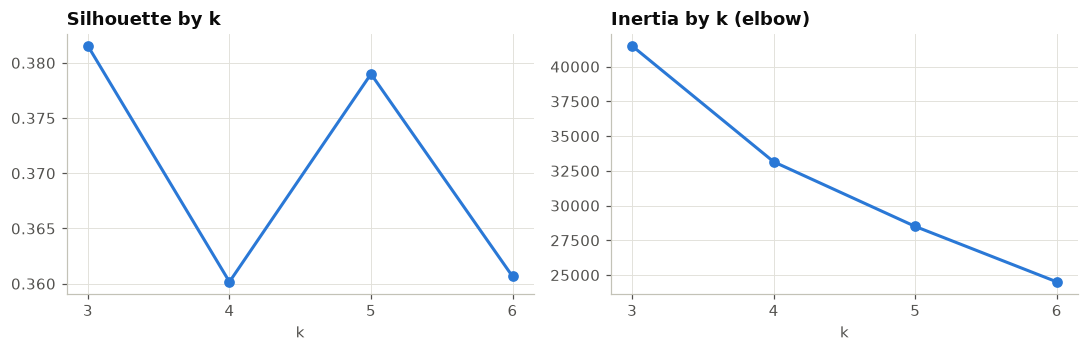

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(sil.index, sil["silhouette"], color=P.BLUE, lw=2, marker="o"); ax[0].set_title("Silhouette by k"); ax[0].set_xlabel("k")
ax[1].plot(sil.index, sil["inertia"], color=P.BLUE, lw=2, marker="o"); ax[1].set_title("Inertia by k (elbow)"); ax[1].set_xlabel("k")
for a in ax: a.set_xticks(list(sil.index))
fig.tight_layout(); P.save(fig, FIG / "15_kmeans_selection.png")

In [24]:
K = 5
print("Chosen k =", K)
km = KMeans(n_clusters=K, n_init=5 if FAST else 10, random_state=SEED).fit(Z)
pos = pos.assign(cluster=km.labels_)
joblib.dump({"scaler": scaler, "kmeans": km}, MODELS / "clusters.joblib", compress=3)

prof = (pos.groupby("cluster").agg(rows=("cluster", "size"), mean_lat=("cell_ll_lat", "mean"), mean_lon=("cell_ll_lon", "mean"),
                                    median_fishing_hours=("fishing_hours", "median"),
                                    top_gear=("geartype", lambda s: s.value_counts().index[0]),
                                    top_gear_share=("geartype", lambda s: s.value_counts(normalize=True).iloc[0])))
RESULTS["D_k"] = K
print("Adjusted Rand index between clusters and gear type:", round(adjusted_rand_score(pos["geartype"], pos["cluster"]), 3),
      "(0 = unrelated, 1 = identical)")
prof.round(2)

Chosen k = 5
Adjusted Rand index between clusters and gear type: 0.033 (0 = unrelated, 1 = identical)


,rows,mean_lat,mean_lon,median_fishing_hours,top_gear,top_gear_share
cluster,,,,,,
0,13829,30.29,112.94,33.47,set_gillnets,0.16
1,20349,26.97,113.41,2.01,fixed_gear,0.11
2,24774,52.47,-16.33,3.12,seiners,0.12
3,7681,-4.11,52.44,3.05,drifting_longlines,0.34
4,6812,-20.69,-71.92,2.74,drifting_longlines,0.29


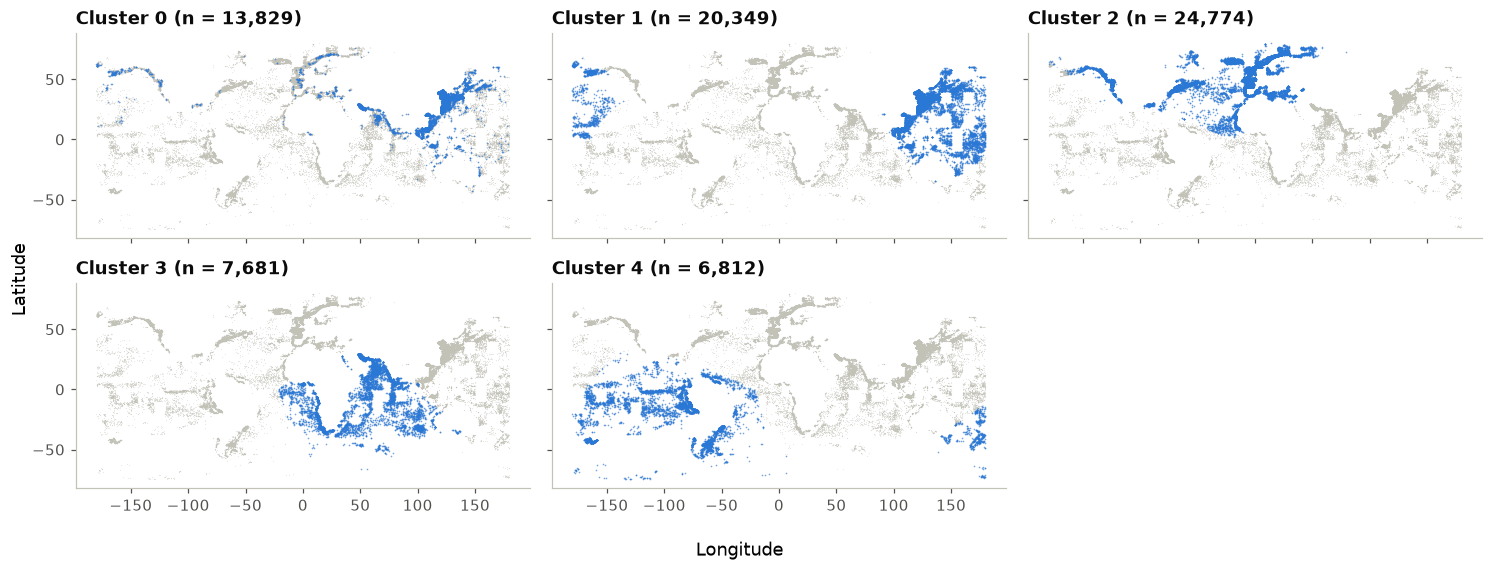

In [25]:
ncol = min(K, 3); nrow = int(np.ceil(K / ncol))
fig, ax = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 2.6 * nrow), sharex=True, sharey=True, squeeze=False)
for c, a in zip(range(K), ax.ravel()):
    a.scatter(pos["cell_ll_lon"], pos["cell_ll_lat"], s=0.5, color="#c3c2b7", linewidths=0, alpha=0.4)
    s = pos[pos["cluster"] == c]
    a.scatter(s["cell_ll_lon"], s["cell_ll_lat"], s=1.2, color=P.BLUE, linewidths=0, alpha=0.6)
    a.set_title(f"Cluster {c} (n = {len(s):,})"); a.grid(False)
for a in ax.ravel()[K:]: a.axis("off")
fig.supxlabel("Longitude"); fig.supylabel("Latitude"); fig.tight_layout(); P.save(fig, FIG / "16_cluster_maps.png")

## Save the cross-validation results

In [26]:
(ROOT / "reports").mkdir(exist_ok=True)
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (np.floating, np.integer)): return float(o)
    return o
with open(ROOT / "reports" / "cv_results.json", "w") as f:
    json.dump(clean(RESULTS), f, indent=2)
print("Saved reports/cv_results.json")
print("Models saved:", sorted(p.name for p in MODELS.glob("*.joblib")))

Saved reports/cv_results.json
Models saved: ['clusters.joblib', 'gear.joblib', 'hours_A.joblib', 'hours_B.joblib', 'occurrence_A.joblib', 'occurrence_B.joblib']


In [ ]:
# To shrink file size

small = clone(searchC["Hist gradient boosting"].best_estimator_)
small.fit(train[GEAR_COLS], train["geartype"])
joblib.dump({"pipeline": small, "columns": GEAR_COLS}, MODELS / "gear.joblib", compress=3)
print(round((MODELS / "gear.joblib").stat().st_size / 1e6, 1), "MB")